# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [ ]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [ ]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [ ]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

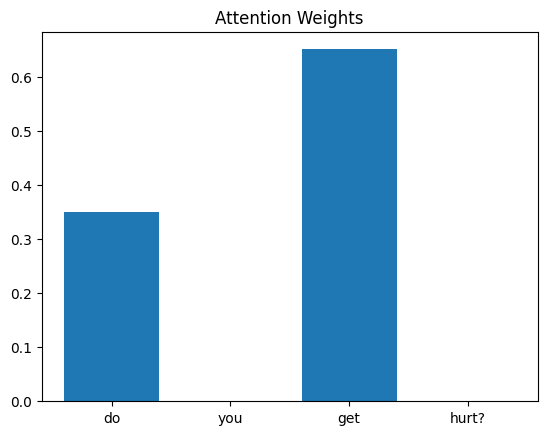

In [ ]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [1]:
# Import libraries
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
import torch
from torch import nn

torch.manual_seed(42)

In [2]:
# Upload the dataset
df = pd.read_csv("Lab_11_QnA_Dataset.csv")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


In [3]:
# Lowercase
df["question"] = df["question"].str.lower()

# Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Make all questions the same length by adding zeros (padding)
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

In [4]:
# Build an RNN with attention
class RNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
    self.rnn = nn.RNN(16, 32)
    self.att = nn.Linear(32, 1)
    self.fc = nn.Linear(32, df["answer_id"].nunique())

  def forward(self, x):
    x, _ = self.rnn(self.emb(x))
    weights = torch.softmax(self.att(x), dim=1)
    return self.fc((x * weights).sum(1)), weights.squeeze(-1)


model = RNN()

In [5]:
# Train the model
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
  loss = nn.functional.cross_entropy(model(X)[0], y)  # calculate loss to reduce it
  loss.backward()  # backpropagation to update parameters
  optimizer.step()  # update parameters

print("Training finished!")

Training finished!


In [6]:
# Select three questions from the dataset
sample_indices = [2, 3, 4]
selected_questions = df.loc[sample_indices, "question"].tolist()

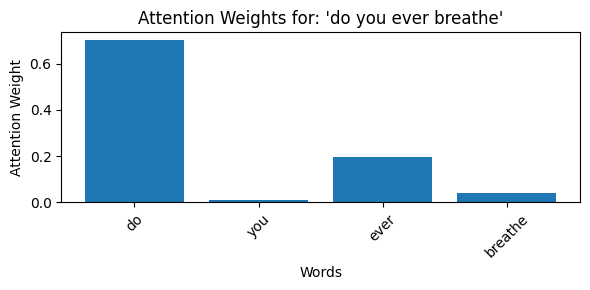

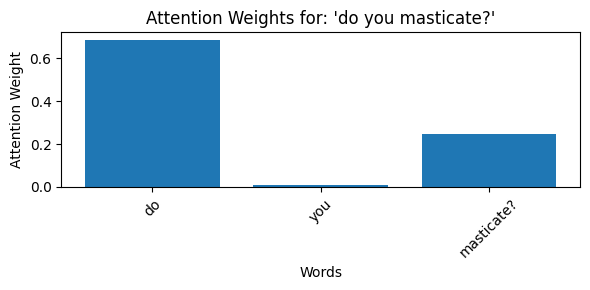

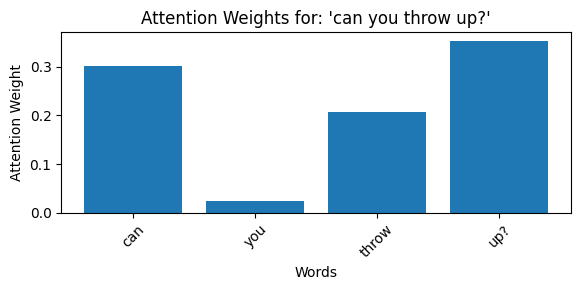

In [23]:
for idx, q in zip(sample_indices, selected_questions):
  # Tokenize and pad the question
  seq = pad_sequences(
      tokenizer.texts_to_sequences([q]), maxlen=X.shape[1], padding="post"
  )
  input_tensor = torch.tensor(seq, dtype=torch.long)

  # Get model predictions and attention weights
  with torch.no_grad():
    prediction, weights = model(input_tensor)

  words = q.split()
  att_weights = weights[0, : len(words)].tolist()

  # Identify the word with the highest attention weight
  max_weight_idx = att_weights.index(max(att_weights))

  # Plotting the bar chart
  plt.figure(figsize=(6, 3))
  plt.bar(words, att_weights)
  plt.title(f"Attention Weights for: '{q}'")
  plt.xlabel("Words")
  plt.ylabel("Attention Weight")
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()

**Answer:**
Yes, the model assigns higher attention weights weights to verbs and question words such as "do", "misticates",or "up". This shows that the attention mechanism alows the RNN to weigh different tokens based on the task, helping the model to foucs on the most relevant words rather than treating all words equally.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

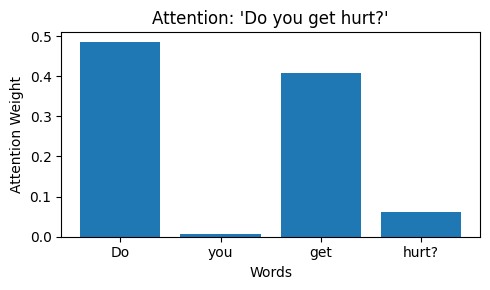

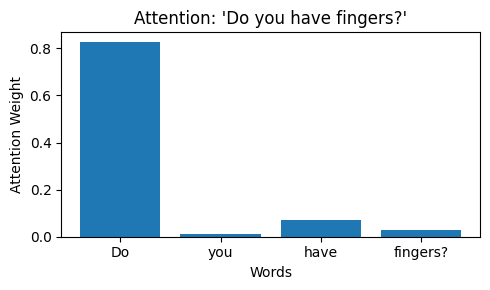

In [25]:
sim_questions = ["Do you get hurt?", "Do you have fingers?"]

for q in sim_questions:
  seq = pad_sequences(
      tokenizer.texts_to_sequences([q]), maxlen=X.shape[1], padding="post"
  )
  input_tensor = torch.tensor(seq, dtype=torch.long)

  with torch.no_grad():
    prediction, weights = model(input_tensor)

  words = q.split()
  att_weights = weights[0, : len(words)].tolist()

  # Plotting
  plt.figure(figsize=(5, 3))
  plt.bar(words, att_weights)
  plt.title(f"Attention: '{q}'")
  plt.xlabel("Words")
  plt.ylabel("Attention Weight")
  plt.tight_layout()
  plt.show()

**Answer:**
When processing questions with similar meaning, the mapping will be to one group so the model focuses heavily on the core terms or auxiliary verbs, while sharing the distribution across the thematic verbs/nouns ("get" vs. "have"). This suggests that the attention mechanism depends on meaning rather than structure. Even if wording changes, the model will lead to the correct output catagory.